# 01 — JPK reader, export and preliminary instrumental QC

Final notebook to:
1. read all `.jpk-force` files;
2. export the `extend/retract` segments to CSV;
3. save the JPK metadata and properties;
4. build the summary of the `segment0/extend` curves;
5. assign a **preliminary instrumental QC**.

This notebook does **not** do contact point, indentation, Hertz/Sneddon fit, Young modulus, final statistics or ML.  
The QC produced here is diagnostic: **no curve is excluded in this notebook**.

Expected input (folder names are kept as in the raw data: `cito` = cytoplasm, `nucleo` = nucleus):

```text
Curve di forza belle/
    Petri20k_MCF7R_t48h_cito_20260225/
    Petri20k_MCF7R_t48h_nucleo_20260225/
    T47DR_t48h_cito_20260318/
    T47DR_t48h_nucleo_20260318/
```

In [1]:
from pathlib import Path
import zipfile
import re
import json
import sys
import platform
import warnings
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 120)
pd.set_option("display.max_rows", 80)

DATA_DIR = Path("Curve di forza belle")

OUT_DIR = Path("afm_output")
CSV_DIR = OUT_DIR / "csv_curves"
META_DIR = OUT_DIR / "metadata"
SUMMARIES_DIR = OUT_DIR / "summaries"
MANIFEST_DIR = OUT_DIR / "manifests"
PLOTS_DIR = OUT_DIR / "plots_overview"
QC_PLOTS_DIR = OUT_DIR / "plots_qc"
REPORTS_DIR = OUT_DIR / "reports"

for d in [OUT_DIR, CSV_DIR, META_DIR, SUMMARIES_DIR, MANIFEST_DIR, PLOTS_DIR, QC_PLOTS_DIR, REPORTS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

SEGMENTS_TO_EXPORT = "all"
BASELINE_FRACTION = 0.20
QC_Z_THRESHOLD = 3.5
SAVE_ALL_OVERVIEW_PLOTS = True
SAVE_QC_EXAMPLE_PLOTS = True

print("Working directory:", Path.cwd())
print("Data directory:", DATA_DIR.resolve())
print("Data directory exists:", DATA_DIR.exists())
print("Output directory:", OUT_DIR.resolve())

if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"DATA_DIR does not exist: {DATA_DIR.resolve()}\n"
        "Put the notebook in the directory that contains 'Curve di forza belle', or edit DATA_DIR."
    )

Working directory: /Users/gmoretti/Work/AFM/Code_General
Data directory: /Users/gmoretti/Work/AFM/Code_General/Curve di forza belle
Data directory exists: True
Output directory: /Users/gmoretti/Work/AFM/Code_General/afm_output


## 1. Utility functions and JPK reading

In [2]:
def parse_properties(text_or_bytes):
    # Simple parser for JPK .properties files.
    if isinstance(text_or_bytes, bytes):
        text = text_or_bytes.decode("utf-8", errors="replace")
    else:
        text = str(text_or_bytes)
    props = {}
    for line in text.splitlines():
        line = line.strip()
        if not line or line.startswith("#") or "=" not in line:
            continue
        k, v = line.split("=", 1)
        props[k.strip()] = v.strip()
    return props


def safe_float(x, default=np.nan):
    try:
        if x is None:
            return default
        x = str(x).replace("\\:", ":").strip()
        if x.lower() in {"nan", "none", ""}:
            return np.nan
        return float(x)
    except Exception:
        return default


def sanitize_name(s):
    s = str(s)
    s = re.sub(r"[^\w\-.]+", "_", s, flags=re.UNICODE)
    return s.strip("_")[:180]


def robust_mad_sigma(x):
    x = np.asarray(x, dtype=float)
    med = np.nanmedian(x)
    mad = np.nanmedian(np.abs(x - med))
    if not np.isfinite(mad):
        return np.nan
    return 1.4826 * mad


def channel_lcd_index(shared_props, channel_name):
    pattern = re.compile(r"lcd-info\.(\d+)\.channel\.name")
    for k, v in shared_props.items():
        m = pattern.fullmatch(k)
        if m and v == channel_name:
            return int(m.group(1))
    return None


def channel_type(shared_props, channel_name):
    idx = channel_lcd_index(shared_props, channel_name)
    if idx is None:
        return None
    return shared_props.get(f"lcd-info.{idx}.type")


def conversion_multiplier(shared_props, channel_name, conversion_name):
    idx = channel_lcd_index(shared_props, channel_name)
    if idx is None:
        return np.nan
    return safe_float(shared_props.get(f"lcd-info.{idx}.conversion-set.conversion.{conversion_name}.scaling.multiplier"))


def conversion_offset(shared_props, channel_name, conversion_name):
    idx = channel_lcd_index(shared_props, channel_name)
    if idx is None:
        return np.nan
    return safe_float(
        shared_props.get(f"lcd-info.{idx}.conversion-set.conversion.{conversion_name}.scaling.offset"),
        0.0,
    )


def read_raw_channel(zf, segment_id, channel_name, shared_props):
    name = f"segments/{segment_id}/channels/{channel_name}.dat"
    if name not in zf.namelist():
        return None

    raw = zf.read(name)
    ctype = channel_type(shared_props, channel_name)

    if ctype == "float-data":
        arr = np.frombuffer(raw, dtype=">f4").astype(float)
    elif ctype == "integer-data":
        arr = np.frombuffer(raw, dtype=">i4").astype(float)
    else:
        arr = np.frombuffer(raw, dtype=">f4").astype(float)

    return arr


def available_segment_channels(zf, segment_id):
    prefix = f"segments/{segment_id}/channels/"
    out = []
    for name in zf.namelist():
        if name.startswith(prefix) and name.endswith(".dat"):
            out.append(Path(name).stem)
    return sorted(out)


def existing_segment_ids(zf):
    ids = set()
    for name in zf.namelist():
        m = re.match(r"segments/(\d+)/segment-header\.properties$", name)
        if m:
            ids.add(int(m.group(1)))
    return sorted(ids)


def generated_time_channel(segment_props):
    n = int(float(segment_props.get(
        "channel.time.data.num-points",
        segment_props.get("force-segment-header.num-points", 0),
    )))
    start = safe_float(segment_props.get("channel.time.data.start"), 0.0)
    step = safe_float(segment_props.get("channel.time.data.step"), np.nan)
    if n <= 0 or not np.isfinite(step):
        return None
    return start + step * np.arange(n)


def list_jpk_files(data_dir=DATA_DIR):
    return sorted(Path(data_dir).rglob("*.jpk-force"))

In [3]:
def read_jpk_segment(file_path, segment_id=0, include_all_channels=True):
    # Read one segment of a .jpk-force file.
    file_path = Path(file_path)

    with zipfile.ZipFile(file_path, "r") as zf:
        names = set(zf.namelist())

        global_props = parse_properties(zf.read("header.properties")) if "header.properties" in names else {}
        shared_props = parse_properties(zf.read("shared-data/header.properties")) if "shared-data/header.properties" in names else {}

        seg_header_name = f"segments/{segment_id}/segment-header.properties"
        if seg_header_name not in names:
            raise ValueError(f"Segment {segment_id} not found in {file_path.name}")

        seg_props = parse_properties(zf.read(seg_header_name))

        z_tip = read_raw_channel(zf, segment_id, "verticalTipPosition", shared_props)
        vdefl_V = read_raw_channel(zf, segment_id, "vDeflection", shared_props)
        h = read_raw_channel(zf, segment_id, "height", shared_props)
        t = generated_time_channel(seg_props)

        if z_tip is None or vdefl_V is None:
            raise ValueError(f"Main channels missing in {file_path.name}, segment {segment_id}")

        n = min(len(z_tip), len(vdefl_V))
        z_tip = z_tip[:n]
        vdefl_V = vdefl_V[:n]
        if h is not None:
            h = h[:n]
        if t is not None:
            t = t[:n]

        sens_m_per_V = conversion_multiplier(shared_props, "vDeflection", "distance")
        spring_N_per_m = conversion_multiplier(shared_props, "vDeflection", "force")

        if not np.isfinite(sens_m_per_V):
            sens_m_per_V = np.nan
        if not np.isfinite(spring_N_per_m):
            spring_N_per_m = np.nan

        deflection_m = vdefl_V * sens_m_per_V if np.isfinite(sens_m_per_V) else np.full_like(vdefl_V, np.nan)
        force_N = deflection_m * spring_N_per_m if np.isfinite(spring_N_per_m) else np.full_like(vdefl_V, np.nan)

        df = pd.DataFrame({
            "point": np.arange(n),
            "time_s": t if t is not None else np.nan,
            "z_tip_m": z_tip,
            "z_tip_um": z_tip * 1e6,
            "vDeflection_V": vdefl_V,
            "deflection_m": deflection_m,
            "deflection_nm": deflection_m * 1e9,
            "force_N": force_N,
            "force_nN": force_N * 1e9,
        })

        if h is not None:
            df["height_raw"] = h

        channel_list = []
        if include_all_channels:
            channel_list = available_segment_channels(zf, segment_id)
            already = {"verticalTipPosition", "vDeflection", "height"}
            for ch in channel_list:
                if ch in already:
                    continue
                arr = read_raw_channel(zf, segment_id, ch, shared_props)
                if arr is None:
                    continue
                if len(arr) >= n:
                    df[f"{ch}_raw"] = arr[:n]

        meta = {
            "file": str(file_path),
            "file_name": file_path.name,
            "group": file_path.parent.name,
            "segment_id": segment_id,
            "segment_style": seg_props.get(
                "force-segment-header.settings.segment-settings.style",
                seg_props.get("force-segment-header.settings.style"),
            ),
            "segment_name": seg_props.get("force-segment-header.name.name"),
            "num_points_header": safe_float(seg_props.get("force-segment-header.num-points")),
            "num_points_read": n,
            "duration_s": safe_float(seg_props.get("force-segment-header.duration")),
            "time_stamp": seg_props.get("force-segment-header.time-stamp"),
            "cantilever_id": seg_props.get("force-segment-header.environment.cantilever-calibration-info.cantilever-id"),
            "cantilever_name": seg_props.get("force-segment-header.environment.cantilever-calibration-info.cantilever-name"),
            "spring_N_per_m": spring_N_per_m,
            "sensitivity_m_per_V": sens_m_per_V,
            "tip_radius": safe_float(seg_props.get("force-segment-header.environment.cantilever-calibration-info.tip-radius")),
            "tip_half_angle": safe_float(seg_props.get("force-segment-header.environment.cantilever-calibration-info.tip-half-angle")),
            "setpoint": safe_float(seg_props.get("force-segment-header.settings.segment-settings.setpoint")),
            "available_channels": ",".join(channel_list),
        }

        return df, meta, global_props, shared_props, seg_props

## 2. Group parsing, preliminary baseline and technical metrics

In [4]:
def parse_group_name(group):
    group = str(group)

    cell_line = np.nan
    if "MCF7R" in group:
        cell_line = "MCF7R"
    elif "T47DR" in group:
        cell_line = "T47DR"

    region = np.nan
    if re.search(r"(^|_)cito(_|$)", group):
        region = "cito"
    elif re.search(r"(^|_)nucleo(_|$)", group):
        region = "nucleo"

    time_h = np.nan
    m_time = re.search(r"t(\d+)h", group)
    if m_time:
        time_h = int(m_time.group(1))

    date = np.nan
    m_date = re.search(r"(\d{8})$", group)
    if m_date:
        date = m_date.group(1)

    seeding = np.nan
    m_petri = re.search(r"(Petri\d+k)", group)
    if m_petri:
        seeding = m_petri.group(1)

    return {
        "cell_line": cell_line,
        "region": region,
        "time_h": time_h,
        "date": date,
        "seeding": seeding,
    }


def assign_analysis_role(segment_style):
    if segment_style == "extend":
        return "mechanical_fit_candidate"
    if segment_style == "retract":
        return "adhesion_hysteresis_candidate"
    return "unknown"


def segment_baseline(force, segment_style=None, frac=BASELINE_FRACTION):
    # Baseline preliminare:
    # extend  -> start of segment, far from the sample;
    # retract -> end of segment, far from the sample.
    f = np.asarray(force, dtype=float)
    n = len(f)
    nbase = max(20, int(frac * n))

    if n == 0:
        return np.nan, np.nan, "empty", 0

    segment_style = str(segment_style).lower()

    if segment_style == "extend":
        base = f[:nbase]
        region = "start_of_extend_far_from_surface"
    elif segment_style == "retract":
        base = f[-nbase:]
        region = "end_of_retract_far_from_surface"
    else:
        left = f[:nbase]
        right = f[-nbase:]
        left_med = np.nanmedian(left)
        right_med = np.nanmedian(right)
        if abs(left_med) <= abs(right_med):
            base = left
            region = "start_auto_closest_to_zero"
        else:
            base = right
            region = "end_auto_closest_to_zero"

    med = float(np.nanmedian(base))
    noise_nN = float(robust_mad_sigma(base))
    return med, noise_nN, region, nbase


def monotonicity_fraction(x, expected):
    x = np.asarray(x, dtype=float)
    if len(x) < 2:
        return np.nan
    dx = np.diff(x)
    if expected == "decreasing":
        return float(np.nanmean(dx <= 0))
    if expected == "increasing":
        return float(np.nanmean(dx >= 0))
    return np.nan


def local_jump_score(force):
    f = np.asarray(force, dtype=float)
    if len(f) < 3:
        return np.nan
    df = np.diff(f)
    sigma = robust_mad_sigma(df)
    if sigma == 0 or not np.isfinite(sigma):
        return np.nan
    return float(np.nanmax(np.abs(df - np.nanmedian(df))) / sigma)


def force_consistency_error_nN(df, spring_N_per_m):
    if "deflection_m" not in df.columns or "force_nN" not in df.columns:
        return np.nan
    if not np.isfinite(spring_N_per_m):
        return np.nan
    force_recomputed = spring_N_per_m * df["deflection_m"].to_numpy(dtype=float) * 1e9
    force_stored = df["force_nN"].to_numpy(dtype=float)
    return float(np.nanmax(np.abs(force_recomputed - force_stored)))

## 3. File catalogue

In [5]:
files = list_jpk_files(DATA_DIR)
print(f"Number of .jpk-force files found: {len(files)}")

if len(files) == 0:
    raise FileNotFoundError("No .jpk-force files found. Check DATA_DIR.")

file_catalog = pd.DataFrame({
    "file": [str(p) for p in files],
    "file_name": [p.name for p in files],
    "group": [p.parent.name for p in files],
    "relative_path": [str(p.relative_to(DATA_DIR)) for p in files],
    "size_MB": [p.stat().st_size / 1024**2 for p in files],
})

parsed = file_catalog["group"].apply(parse_group_name).apply(pd.Series)
file_catalog = pd.concat([file_catalog, parsed], axis=1)

file_catalog_path = META_DIR / "file_catalog.csv"
file_catalog.to_csv(file_catalog_path, index=False)

print("Salvato:", file_catalog_path)
display(file_catalog.groupby(["group", "cell_line", "region", "time_h", "date"], dropna=False).size().reset_index(name="n_curves"))
display(file_catalog.head())

Number of .jpk-force files found: 257
Salvato: afm_output/metadata/file_catalog.csv


,group,cell_line,region,time_h,date,n_curves
0,Petri20k_MCF7R_t48h_cito_20260225,MCF7R,cito,48,20260225,55
1,Petri20k_MCF7R_t48h_nucleo_20260225,MCF7R,nucleo,48,20260225,60
2,T47DR_t48h_cito_20260318,T47DR,cito,48,20260318,59
3,T47DR_t48h_nucleo_20260318,T47DR,nucleo,48,20260318,83


,file,file_name,group,relative_path,size_MB,cell_line,region,time_h,date,seeding
0,Curve di forza belle/Petri20k_MCF7R_t48h_cito_...,cito-0000.jpk-force,Petri20k_MCF7R_t48h_cito_20260225,Petri20k_MCF7R_t48h_cito_20260225/cito-0000.jp...,0.307924,MCF7R,cito,48,20260225,Petri20k
1,Curve di forza belle/Petri20k_MCF7R_t48h_cito_...,cito-0005.jpk-force,Petri20k_MCF7R_t48h_cito_20260225,Petri20k_MCF7R_t48h_cito_20260225/cito-0005.jp...,0.275989,MCF7R,cito,48,20260225,Petri20k
2,Curve di forza belle/Petri20k_MCF7R_t48h_cito_...,cito-0006.jpk-force,Petri20k_MCF7R_t48h_cito_20260225,Petri20k_MCF7R_t48h_cito_20260225/cito-0006.jp...,0.293143,MCF7R,cito,48,20260225,Petri20k
3,Curve di forza belle/Petri20k_MCF7R_t48h_cito_...,cito-0007.jpk-force,Petri20k_MCF7R_t48h_cito_20260225,Petri20k_MCF7R_t48h_cito_20260225/cito-0007.jp...,0.306417,MCF7R,cito,48,20260225,Petri20k
4,Curve di forza belle/Petri20k_MCF7R_t48h_cito_...,cito-0008.jpk-force,Petri20k_MCF7R_t48h_cito_20260225,Petri20k_MCF7R_t48h_cito_20260225/cito-0008.jp...,0.307043,MCF7R,cito,48,20260225,Petri20k


## 4. Inspection of an example file

In [6]:
example_file = files[0]
print("Example file:", example_file)

for seg in [0, 1]:
    try:
        df_seg, meta_seg, *_ = read_jpk_segment(example_file, segment_id=seg)
        print(f"\nSegment {seg}")
        for k in [
            "segment_name", "segment_style", "num_points_read", "duration_s",
            "spring_N_per_m", "sensitivity_m_per_V", "cantilever_name", "available_channels"
        ]:
            print(f"  {k}: {meta_seg.get(k)}")
        display(df_seg.head())
    except Exception as e:
        print(f"Segment {seg} not readable: {e}")

Example file: Curve di forza belle/Petri20k_MCF7R_t48h_cito_20260225/cito-0000.jpk-force

Segment 0
  segment_name: extend-spm
  segment_style: extend
  num_points_read: 6000
  duration_s: 1.0
  spring_N_per_m: 0.11882854247819882
  sensitivity_m_per_V: 1.0902786667117663e-08
  cantilever_name: MLCT-BIO-Triangular
  available_channels: combinedHeight,combinedHeightMeasured,error,hDeflection,height,measuredHeight,smoothedMeasuredHeight,vDeflection,verticalTipPosition


,point,time_s,z_tip_m,z_tip_um,vDeflection_V,deflection_m,deflection_nm,force_N,force_nN,height_raw,combinedHeight_raw,combinedHeightMeasured_raw,error_raw,hDeflection_raw,measuredHeight_raw,smoothedMeasuredHeight_raw
0,0,0.000083,-0.000009,-9.411679,-0.002549,-2.778649e-11,-0.027786,-3.301828e-12,-0.003302,-1.731205e+09,-0.016369,-0.016374,543794.0,-9319651.0,-709634120.0,-0.000009
1,1,0.000250,-0.000009,-9.412655,-0.000184,-2.009426e-12,-0.002009,-2.387772e-13,-0.000239,-1.730781e+09,-0.016369,-0.016374,540480.0,-9253919.0,-709569433.0,-0.000009
2,2,0.000417,-0.000009,-9.413626,0.002801,3.053934e-11,0.030539,3.628945e-12,0.003629,-1.730358e+09,-0.016369,-0.016374,544312.0,-8869765.0,-709512078.0,-0.000009
3,3,0.000583,-0.000009,-9.414609,0.004604,5.019405e-11,0.050194,5.964486e-12,0.005964,-1.729937e+09,-0.016369,-0.016374,534925.0,-9029056.0,-709441500.0,-0.000009
4,4,0.000750,-0.000009,-9.415619,0.003924,4.278044e-11,0.042780,5.083537e-12,0.005084,-1.729515e+09,-0.016369,-0.016374,545534.0,-9231354.0,-709390735.0,-0.000009



Segment 1
  segment_name: retract-spm
  segment_style: retract
  num_points_read: 6000
  duration_s: 1.0
  spring_N_per_m: 0.11882854247819882
  sensitivity_m_per_V: 1.0902786667117663e-08
  cantilever_name: MLCT-BIO-Triangular
  available_channels: combinedHeight,combinedHeightMeasured,error,hDeflection,height,measuredHeight,smoothedMeasuredHeight,vDeflection,verticalTipPosition


,point,time_s,z_tip_m,z_tip_um,vDeflection_V,deflection_m,deflection_nm,force_N,force_nN,height_raw,combinedHeight_raw,combinedHeightMeasured_raw,error_raw,hDeflection_raw,measuredHeight_raw,smoothedMeasuredHeight_raw
0,0,0.000083,-0.000015,-15.422782,0.491876,5.362820e-09,5.362820,6.372561e-10,0.637256,-46054326.0,-0.016374,-0.01638,160871.0,-12876255.0,-341807434.0,-0.000015
1,1,0.000250,-0.000015,-15.422209,0.452404,4.932463e-09,4.932463,5.861174e-10,0.586117,-45968748.0,-0.016374,-0.01638,66869.0,-12998889.0,-341774806.0,-0.000015
2,2,0.000417,-0.000015,-15.421027,0.468966,5.113040e-09,5.113040,6.075751e-10,0.607575,-45950072.0,-0.016374,-0.01638,-29813.0,-13020473.0,-341739499.0,-0.000015
3,3,0.000583,-0.000015,-15.420144,0.457931,4.992722e-09,4.992722,5.932779e-10,0.593278,-46003619.0,-0.016374,-0.01638,-99297.0,-12717834.0,-341731206.0,-0.000015
4,4,0.000750,-0.000015,-15.419120,0.459886,5.014041e-09,5.014041,5.958112e-10,0.595811,-46110322.0,-0.016374,-0.01638,-173179.0,-13039899.0,-341718514.0,-0.000015


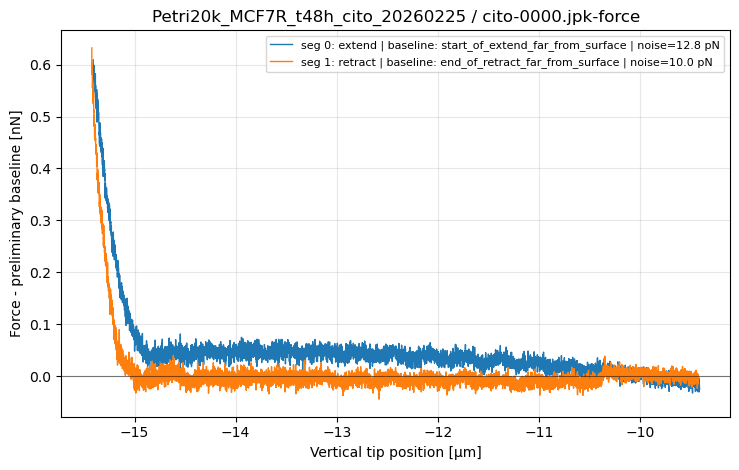

In [7]:
def plot_curve_overview(file_path, save=False):
    file_path = Path(file_path)
    fig, ax = plt.subplots(figsize=(7.5, 4.8))
    plotted = False

    for seg in [0, 1]:
        try:
            df, meta, *_ = read_jpk_segment(file_path, segment_id=seg)
            if df is None or len(df) == 0:
                continue

            z = df["z_tip_um"].to_numpy(dtype=float)
            f = df["force_nN"].to_numpy(dtype=float)
            baseline, noise_nN, region, _ = segment_baseline(f, meta.get("segment_style"), frac=BASELINE_FRACTION)
            f_corr = f - baseline

            label = (
                f"seg {seg}: {meta.get('segment_style')} | "
                f"baseline: {region} | noise={noise_nN*1000:.1f} pN"
            )
            ax.plot(z, f_corr, lw=1, label=label)
            plotted = True
        except Exception as e:
            print(f"Error plotting segment {seg} for {file_path.name}: {e}")

    ax.axhline(0, color="black", lw=0.8, alpha=0.5)
    ax.set_xlabel("Vertical tip position [µm]")
    ax.set_ylabel("Force - preliminary baseline [nN]")
    ax.set_title(f"{file_path.parent.name} / {file_path.name}")
    ax.grid(alpha=0.3)

    if plotted:
        ax.legend(fontsize=8)

    fig.tight_layout()

    if save:
        out = PLOTS_DIR / f"{sanitize_name(file_path.parent.name)}__{sanitize_name(file_path.stem)}.png"
        fig.savefig(out, dpi=180, bbox_inches="tight")
        plt.close(fig)
        return out

    plt.show()
    return None

plot_curve_overview(example_file, save=False)

## 5. Export of the segments to CSV and metadata

In [8]:
def add_properties_rows(properties_rows, file_path, segment_id, global_props, shared_props, seg_props):
    for source_name, props in [
        ("global_header", global_props),
        ("shared_header", shared_props),
        ("segment_header", seg_props),
    ]:
        for k, v in props.items():
            properties_rows.append({
                "file": str(file_path),
                "file_name": Path(file_path).name,
                "group": Path(file_path).parent.name,
                "segment_id": segment_id,
                "source": source_name,
                "key": k,
                "value": v,
            })


def export_segments_to_csv(files, segments_to_export=SEGMENTS_TO_EXPORT):
    metadata_rows = []
    properties_rows = []
    exported_rows = []
    errors = []

    for i, file_path in enumerate(files, start=1):
        file_path = Path(file_path)

        try:
            with zipfile.ZipFile(file_path, "r") as zf:
                seg_ids = existing_segment_ids(zf)
        except Exception as e:
            errors.append({"file": str(file_path), "segment_id": np.nan, "stage": "open_zip", "error": repr(e)})
            continue

        chosen_segments = seg_ids if segments_to_export == "all" else list(segments_to_export)

        for segment_id in chosen_segments:
            try:
                df, meta, global_props, shared_props, seg_props = read_jpk_segment(file_path, segment_id=segment_id)

                parsed = parse_group_name(meta.get("group"))
                meta.update(parsed)
                meta["analysis_role"] = assign_analysis_role(meta.get("segment_style"))

                baseline_nN, noise_nN, baseline_region, nbase = segment_baseline(
                    df["force_nN"], meta.get("segment_style"), frac=BASELINE_FRACTION
                )
                df["force_corr_nN"] = df["force_nN"] - baseline_nN

                for k, v in meta.items():
                    df[f"meta_{k}"] = v

                df["meta_baseline_nN_preliminary"] = baseline_nN
                df["meta_baseline_noise_pN_preliminary"] = noise_nN * 1000.0
                df["meta_baseline_region_preliminary"] = baseline_region

                group_dir = CSV_DIR / sanitize_name(file_path.parent.name)
                group_dir.mkdir(parents=True, exist_ok=True)

                out_name = f"{sanitize_name(file_path.stem)}_segment{segment_id}.csv"
                out_path = group_dir / out_name
                df.to_csv(out_path, index=False)

                meta.update({
                    "baseline_nN_preliminary": baseline_nN,
                    "baseline_noise_pN_preliminary": noise_nN * 1000.0,
                    "baseline_region_preliminary": baseline_region,
                    "baseline_n_points_preliminary": nbase,
                    "csv_path": str(out_path),
                })

                metadata_rows.append(meta)
                add_properties_rows(properties_rows, file_path, segment_id, global_props, shared_props, seg_props)

                exported_rows.append({
                    "file": str(file_path),
                    "file_name": file_path.name,
                    "group": file_path.parent.name,
                    "segment_id": segment_id,
                    "csv_path": str(out_path),
                    "n_points": len(df),
                })

            except Exception as e:
                errors.append({"file": str(file_path), "segment_id": segment_id, "stage": "read_or_export", "error": repr(e)})

        if i % 50 == 0:
            print(f"Processati {i}/{len(files)} file...")

    metadata_segments = pd.DataFrame(metadata_rows)
    properties_long = pd.DataFrame(properties_rows)
    export_manifest = pd.DataFrame(exported_rows)
    errors_df = pd.DataFrame(errors)

    metadata_segments_path = META_DIR / "metadata_segments.csv"
    properties_long_path = META_DIR / "metadata_properties_long.csv"
    export_manifest_path = META_DIR / "csv_export_manifest.csv"
    errors_path = META_DIR / "csv_export_errors.csv"

    metadata_segments.to_csv(metadata_segments_path, index=False)
    properties_long.to_csv(properties_long_path, index=False)
    export_manifest.to_csv(export_manifest_path, index=False)
    errors_df.to_csv(errors_path, index=False)

    print("Metadata segmenti salvati:", metadata_segments_path)
    print("Properties long salvate:", properties_long_path)
    print("Manifest export salvato:", export_manifest_path)
    print("Errori export salvati:", errors_path)
    print(f"Segmenti esportati: {len(export_manifest)}")
    print(f"Errori: {len(errors_df)}")

    return metadata_segments, properties_long, export_manifest, errors_df

metadata_segments, properties_long, export_manifest, export_errors = export_segments_to_csv(files)
display(metadata_segments.head())
display(export_errors.head())

Processati 50/257 file...
Processati 100/257 file...
Processati 150/257 file...
Processati 200/257 file...
Processati 250/257 file...
Metadata segmenti salvati: afm_output/metadata/metadata_segments.csv
Properties long salvate: afm_output/metadata/metadata_properties_long.csv
Manifest export salvato: afm_output/metadata/csv_export_manifest.csv
Errori export salvati: afm_output/metadata/csv_export_errors.csv
Segmenti esportati: 514
Errori: 0


,file,file_name,group,segment_id,segment_style,segment_name,num_points_header,num_points_read,duration_s,time_stamp,cantilever_id,cantilever_name,spring_N_per_m,sensitivity_m_per_V,tip_radius,tip_half_angle,setpoint,available_channels,cell_line,region,time_h,date,seeding,analysis_role,baseline_nN_preliminary,baseline_noise_pN_preliminary,baseline_region_preliminary,baseline_n_points_preliminary,csv_path
0,Curve di forza belle/Petri20k_MCF7R_t48h_cito_...,cito-0000.jpk-force,Petri20k_MCF7R_t48h_cito_20260225,0,extend,extend-spm,6000.0,6000,1.000000,2026-02-25 09\:09\:43.503 +0100,2300FE,MLCT-BIO-Triangular,0.118829,1.090279e-08,NaN,NaN,0.578899,"combinedHeight,combinedHeightMeasured,error,hD...",MCF7R,cito,48,20260225,Petri20k,mechanical_fit_candidate,0.021959,12.778282,start_of_extend_far_from_surface,1200,afm_output/csv_curves/Petri20k_MCF7R_t48h_cito...
1,Curve di forza belle/Petri20k_MCF7R_t48h_cito_...,cito-0000.jpk-force,Petri20k_MCF7R_t48h_cito_20260225,1,retract,retract-spm,6000.0,6000,1.000000,2026-02-25 09\:09\:44.504 +0100,2300FE,MLCT-BIO-Triangular,0.118829,1.090279e-08,NaN,NaN,NaN,"combinedHeight,combinedHeightMeasured,error,hD...",MCF7R,cito,48,20260225,Petri20k,adhesion_hysteresis_candidate,0.005081,10.045133,end_of_retract_far_from_surface,1200,afm_output/csv_curves/Petri20k_MCF7R_t48h_cito...
2,Curve di forza belle/Petri20k_MCF7R_t48h_cito_...,cito-0005.jpk-force,Petri20k_MCF7R_t48h_cito_20260225,0,extend,extend-spm,4700.0,4700,0.783333,2026-02-25 09\:11\:47.886 +0100,2300FE,MLCT-BIO-Triangular,0.118829,1.090279e-08,NaN,NaN,0.578899,"combinedHeight,combinedHeightMeasured,error,hD...",MCF7R,cito,48,20260225,Petri20k,mechanical_fit_candidate,0.034312,11.057050,start_of_extend_far_from_surface,940,afm_output/csv_curves/Petri20k_MCF7R_t48h_cito...
3,Curve di forza belle/Petri20k_MCF7R_t48h_cito_...,cito-0005.jpk-force,Petri20k_MCF7R_t48h_cito_20260225,1,retract,retract-spm,6000.0,6000,1.000000,2026-02-25 09\:11\:48.886 +0100,2300FE,MLCT-BIO-Triangular,0.118829,1.090279e-08,NaN,NaN,NaN,"combinedHeight,combinedHeightMeasured,error,hD...",MCF7R,cito,48,20260225,Petri20k,adhesion_hysteresis_candidate,-0.005687,8.936139,end_of_retract_far_from_surface,1200,afm_output/csv_curves/Petri20k_MCF7R_t48h_cito...
4,Curve di forza belle/Petri20k_MCF7R_t48h_cito_...,cito-0006.jpk-force,Petri20k_MCF7R_t48h_cito_20260225,0,extend,extend-spm,5413.0,5413,0.902167,2026-02-25 09\:11\:49.808 +0100,2300FE,MLCT-BIO-Triangular,0.118829,1.090279e-08,NaN,NaN,0.578899,"combinedHeight,combinedHeightMeasured,error,hD...",MCF7R,cito,48,20260225,Petri20k,mechanical_fit_candidate,0.025869,10.533824,start_of_extend_far_from_surface,1082,afm_output/csv_curves/Petri20k_MCF7R_t48h_cito...


""


## 6. Technical checks of the export

In [9]:
csv_exported = sorted(CSV_DIR.rglob("*.csv"))

print("JPK files:", len(files))
print("CSV exported:", len(csv_exported))
print("metadata rows:", len(metadata_segments))
print("export errors:", len(export_errors))

display(pd.crosstab(metadata_segments["segment_id"], metadata_segments["segment_style"]))
display(pd.crosstab(metadata_segments["segment_id"], metadata_segments["segment_name"]))
display(pd.crosstab(metadata_segments["group"], metadata_segments["segment_id"]))

expected_csv = 2 * len(files)
if len(csv_exported) != expected_csv:
    warnings.warn(f"Exported CSV count = {len(csv_exported)}, expected about {expected_csv} if every file has 2 segments.")

if len(metadata_segments) != len(csv_exported):
    warnings.warn("metadata_segments and exported CSV have different counts.")

dup_csv = export_manifest["csv_path"].duplicated().sum()
dup_file_seg = export_manifest.duplicated(subset=["file", "segment_id"]).sum()

print("Duplicated csv_path:", dup_csv)
print("Duplicated (file, segment_id):", dup_file_seg)

if dup_csv > 0 or dup_file_seg > 0:
    warnings.warn("Attenzione: possibili duplicati nell'export.")

JPK files: 257
CSV exported: 514
metadata rows: 514
export errors: 0


segment_style,extend,retract
segment_id,,
0,257,0
1,0,257


segment_name,extend-spm,retract-spm
segment_id,,
0,257,0
1,0,257


segment_id,0,1
group,,
Petri20k_MCF7R_t48h_cito_20260225,55,55
Petri20k_MCF7R_t48h_nucleo_20260225,60,60
T47DR_t48h_cito_20260318,59,59
T47DR_t48h_nucleo_20260318,83,83


Duplicated csv_path: 0
Duplicated (file, segment_id): 0


In [10]:
calib_table = (
    metadata_segments
    .groupby("group")[["spring_N_per_m", "sensitivity_m_per_V"]]
    .agg(["count", "mean", "std", "min", "max"])
)

display(calib_table)

tip_missing = metadata_segments[["tip_radius", "tip_half_angle"]].isna().mean().rename("fraction_missing")
display(tip_missing)

print(
    "\nNote: if tip_radius and tip_half_angle are missing, notebook 02 can only do empirical fits "
    "or relative stiffness; an absolute Young modulus will need external information "
    "on the tip geometry and on the Poisson ratio."
)

spring_N_per_m                           \
                                             count      mean  std       min   
group                                                                         
Petri20k_MCF7R_t48h_cito_20260225              110  0.118829  0.0  0.118829   
Petri20k_MCF7R_t48h_nucleo_20260225            120  0.118829  0.0  0.118829   
T47DR_t48h_cito_20260318                       118  0.080043  0.0  0.080043   
T47DR_t48h_nucleo_20260318                     166  0.080043  0.0  0.080043   

                                              sensitivity_m_per_V  \
                                          max               count   
group                                                               
Petri20k_MCF7R_t48h_cito_20260225    0.118829                 110   
Petri20k_MCF7R_t48h_nucleo_20260225  0.118829                 120   
T47DR_t48h_cito_20260318             0.080043                 118   
T47DR_t48h_nucleo_20260318           0.080043                 166   

                                                                      \
                                             mean  std           min   
group                                                                  
Petri20k_MCF7R_t48h_cito_20260225    1.090279e-08  0.0  1.090279e-08   
Petri20k_MCF7R_t48h_nucleo_20260225  1.090279e-08  0.0  1.090279e-08   
T47DR_t48h_cito_20260318             1.399632e-08  0.0  1.399632e-08   
T47DR_t48h_nucleo_20260318           1.399632e-08  0.0  1.399632e-08   

                                                   
                                              max  
group                                              
Petri20k_MCF7R_t48h_cito_20260225    1.090279e-08  
Petri20k_MCF7R_t48h_nucleo_20260225  1.090279e-08  
T47DR_t48h_cito_20260318             1.399632e-08  
T47DR_t48h_nucleo_20260318           1.399632e-08

tip_radius        1.0
tip_half_angle    1.0
Name: fraction_missing, dtype: float64


Note: if tip_radius e tip_half_angle sono mancanti, il notebook 03 potrà fare fit empirici o stiffness relative, ma per un modulo di Young assoluto servirà informazione esterna sulla geometria della punta e sul Poisson ratio.


## 7. Building the summary for `segment0/extend`

In [11]:
def summarize_segment_csv(csv_path):
    csv_path = Path(csv_path)
    df = pd.read_csv(csv_path)

    if len(df) == 0:
        return {"status": "empty", "csv_path": str(csv_path), "file_name": csv_path.name}

    def meta_value(name, default=np.nan):
        col = f"meta_{name}"
        if col in df.columns:
            return df[col].iloc[0]
        return default

    file_path = meta_value("file", np.nan)
    group = meta_value("group", csv_path.parent.name)
    file_name = meta_value("file_name", csv_path.name)
    segment_id = int(meta_value("segment_id", -1))
    segment_style = meta_value("segment_style", np.nan)
    segment_name = meta_value("segment_name", np.nan)
    parsed = parse_group_name(group)

    z = df["z_tip_um"].to_numpy(dtype=float)
    f = df["force_nN"].to_numpy(dtype=float)

    baseline_nN, noise_nN, baseline_region, nbase = segment_baseline(f, segment_style, frac=BASELINE_FRACTION)
    f_corr = f - baseline_nN

    z_start = float(z[0]) if len(z) else np.nan
    z_end = float(z[-1]) if len(z) else np.nan
    z_direction = "increasing" if z_end > z_start else "decreasing"

    expected_z = "decreasing" if segment_style == "extend" else "increasing" if segment_style == "retract" else None
    z_mono_frac = monotonicity_fraction(z, expected_z)

    force_start_nN = float(np.nanmedian(f[:nbase])) if len(f) else np.nan
    force_end_nN = float(np.nanmedian(f[-nbase:])) if len(f) else np.nan
    force_delta_nN = force_end_nN - force_start_nN

    baseline_noise_pN = noise_nN * 1000.0
    signal_to_noise = np.nan
    if np.isfinite(baseline_noise_pN) and baseline_noise_pN > 0:
        signal_to_noise = float(np.nanmax(f_corr) / (baseline_noise_pN * 1e-3))

    spring_N_per_m = safe_float(meta_value("spring_N_per_m", np.nan))
    force_consistency_max_abs_error_nN = force_consistency_error_nN(df, spring_N_per_m)

    return {
        "status": "ok",
        "file": file_path,
        "file_name": file_name,
        "group": group,
        **parsed,
        "csv_path": str(csv_path),
        "segment_id": segment_id,
        "segment_style": segment_style,
        "segment_name": segment_name,
        "analysis_role": assign_analysis_role(segment_style),
        "n_points": int(len(df)),
        "duration_s": safe_float(meta_value("duration_s", np.nan)),
        "z_start_um": z_start,
        "z_end_um": z_end,
        "z_direction": z_direction,
        "z_expected_direction": expected_z,
        "z_monotonicity_fraction": z_mono_frac,
        "z_min_um": float(np.nanmin(z)),
        "z_max_um": float(np.nanmax(z)),
        "z_range_um": float(np.nanmax(z) - np.nanmin(z)),
        "force_min_nN": float(np.nanmin(f)),
        "force_max_nN": float(np.nanmax(f)),
        "force_start_nN": force_start_nN,
        "force_end_nN": force_end_nN,
        "force_delta_nN": force_delta_nN,
        "baseline_nN": baseline_nN,
        "baseline_noise_pN": baseline_noise_pN,
        "baseline_region": baseline_region,
        "baseline_n_points": nbase,
        "force_corr_min_nN": float(np.nanmin(f_corr)),
        "force_corr_max_nN": float(np.nanmax(f_corr)),
        "force_corr_start_nN": float(np.nanmedian(f_corr[:nbase])),
        "force_corr_end_nN": float(np.nanmedian(f_corr[-nbase:])),
        "signal_to_noise": signal_to_noise,
        "force_jump_score": local_jump_score(f_corr),
        "force_consistency_max_abs_error_nN": force_consistency_max_abs_error_nN,
        "n_nan_z": int(pd.Series(df["z_tip_um"]).isna().sum()),
        "n_nan_force": int(pd.Series(df["force_nN"]).isna().sum()),
        "n_inf_z": int(np.isinf(df["z_tip_um"].to_numpy(dtype=float)).sum()),
        "n_inf_force": int(np.isinf(df["force_nN"].to_numpy(dtype=float)).sum()),
        "spring_N_per_m": spring_N_per_m,
        "sensitivity_m_per_V": safe_float(meta_value("sensitivity_m_per_V", np.nan)),
        "cantilever_name": meta_value("cantilever_name", np.nan),
        "cantilever_id": meta_value("cantilever_id", np.nan),
        "tip_radius": safe_float(meta_value("tip_radius", np.nan)),
        "tip_half_angle": safe_float(meta_value("tip_half_angle", np.nan)),
        "time_stamp": meta_value("time_stamp", np.nan),
        "available_channels": meta_value("available_channels", np.nan),
    }


segment0_csv = sorted(CSV_DIR.rglob("*_segment0.csv"))
summary_rows = []

for p in segment0_csv:
    try:
        summary_rows.append(summarize_segment_csv(p))
    except Exception as e:
        summary_rows.append({
            "status": "error",
            "csv_path": str(p),
            "file_name": p.name,
            "group": p.parent.name,
            "error": repr(e),
        })

summary = pd.DataFrame(summary_rows)

summary_path = SUMMARIES_DIR / "summary_segment0.csv"
summary.to_csv(summary_path, index=False)

print("Summary segment0 salvato:", summary_path)
print("Righe:", len(summary))
display(summary["status"].value_counts(dropna=False))
display(summary.groupby(["group", "cell_line", "region"], dropna=False).size().reset_index(name="n_curves"))
display(summary.head())

Summary segment0 salvato: afm_output/summaries/summary_segment0.csv
Righe: 257


status
ok    257
Name: count, dtype: int64

,group,cell_line,region,n_curves
0,Petri20k_MCF7R_t48h_cito_20260225,MCF7R,cito,55
1,Petri20k_MCF7R_t48h_nucleo_20260225,MCF7R,nucleo,60
2,T47DR_t48h_cito_20260318,T47DR,cito,59
3,T47DR_t48h_nucleo_20260318,T47DR,nucleo,83


,status,file,file_name,group,cell_line,region,time_h,date,seeding,csv_path,segment_id,segment_style,segment_name,analysis_role,n_points,duration_s,z_start_um,z_end_um,z_direction,z_expected_direction,z_monotonicity_fraction,z_min_um,z_max_um,z_range_um,force_min_nN,force_max_nN,force_start_nN,force_end_nN,force_delta_nN,baseline_nN,baseline_noise_pN,baseline_region,baseline_n_points,force_corr_min_nN,force_corr_max_nN,force_corr_start_nN,force_corr_end_nN,signal_to_noise,force_jump_score,force_consistency_max_abs_error_nN,n_nan_z,n_nan_force,n_inf_z,n_inf_force,spring_N_per_m,sensitivity_m_per_V,cantilever_name,cantilever_id,tip_radius,tip_half_angle,time_stamp,available_channels
0,ok,Curve di forza belle/Petri20k_MCF7R_t48h_cito_...,cito-0000.jpk-force,Petri20k_MCF7R_t48h_cito_20260225,MCF7R,cito,48,20260225,Petri20k,afm_output/csv_curves/Petri20k_MCF7R_t48h_cito...,0,extend,extend-spm,mechanical_fit_candidate,6000,1.000000,-9.411679,-15.409008,decreasing,decreasing,1.0,-15.409008,-9.411679,5.997330,-0.010746,0.631120,0.021959,0.074320,0.052361,0.021959,12.778282,start_of_extend_far_from_surface,1200,-0.032705,0.609161,-1.734723e-18,0.052361,47.671563,5.190048,2.220446e-16,0,0,0,0,0.118829,1.090279e-08,MLCT-BIO-Triangular,2300FE,NaN,NaN,2026-02-25 09\:09\:43.503 +0100,"combinedHeight,combinedHeightMeasured,error,hD..."
1,ok,Curve di forza belle/Petri20k_MCF7R_t48h_cito_...,cito-0005.jpk-force,Petri20k_MCF7R_t48h_cito_20260225,MCF7R,cito,48,20260225,Petri20k,afm_output/csv_curves/Petri20k_MCF7R_t48h_cito...,0,extend,extend-spm,mechanical_fit_candidate,4700,0.783333,-10.896858,-15.592912,decreasing,decreasing,1.0,-15.592912,-10.896858,4.696054,0.002368,0.741301,0.034312,0.122009,0.087697,0.034312,11.057050,start_of_extend_far_from_surface,940,-0.031944,0.706989,0.000000e+00,0.087697,63.940088,4.130746,3.330669e-16,0,0,0,0,0.118829,1.090279e-08,MLCT-BIO-Triangular,2300FE,NaN,NaN,2026-02-25 09\:11\:47.886 +0100,"combinedHeight,combinedHeightMeasured,error,hD..."
2,ok,Curve di forza belle/Petri20k_MCF7R_t48h_cito_...,cito-0006.jpk-force,Petri20k_MCF7R_t48h_cito_20260225,MCF7R,cito,48,20260225,Petri20k,afm_output/csv_curves/Petri20k_MCF7R_t48h_cito...,0,extend,extend-spm,mechanical_fit_candidate,5413,0.902167,-10.357957,-15.767386,decreasing,decreasing,1.0,-15.767386,-10.357957,5.409429,-0.090425,0.596325,0.025869,0.204638,0.178769,0.025869,10.533824,start_of_extend_far_from_surface,1082,-0.116293,0.570457,-1.734723e-18,0.178769,54.154761,5.206711,3.330669e-16,0,0,0,0,0.118829,1.090279e-08,MLCT-BIO-Triangular,2300FE,NaN,NaN,2026-02-25 09\:11\:49.808 +0100,"combinedHeight,combinedHeightMeasured,error,hD..."
3,ok,Curve di forza belle/Petri20k_MCF7R_t48h_cito_...,cito-0007.jpk-force,Petri20k_MCF7R_t48h_cito_20260225,MCF7R,cito,48,20260225,Petri20k,afm_output/csv_curves/Petri20k_MCF7R_t48h_cito...,0,extend,extend-spm,mechanical_fit_candidate,6000,1.000000,-9.624797,-15.621139,decreasing,decreasing,1.0,-15.621139,-9.624797,5.996342,0.071084,0.656569,0.102729,0.150196,0.047467,0.102729,10.392184,start_of_extend_far_from_surface,1200,-0.031645,0.553840,0.000000e+00,0.047467,53.293868,3.977025,3.330669e-16,0,0,0,0,0.118829,1.090279e-08,MLCT-BIO-Triangular,2300FE,NaN,NaN,2026-02-25 09\:11\:51.934 +0100,"combinedHeight,combinedHeightMeasured,error,hD..."
4,ok,Curve di forza belle/Petri20k_MCF7R_t48h_cito_...,cito-0008.jpk-force,Petri20k_MCF7R_t48h_cito_20260225,MCF7R,cito,48,20260225,Petri20k,afm_output/csv_curves/Petri20k_MCF7R_t48h_cito...,0,extend,extend-spm,mechanical_fit_candidate,6000,1.000000,-9.651365,-15.645828,decreasing,decreasing,1.0,-15.645828,-9.651365,5.994463,0.013170,0.813682,0.046276,0.137774,0.091498,0.046276,11.176091,start_of_extend_far_from_surface,1200,-0.033106,0.767406,3.469447e-18,0.091498,68.664955,4.129775,3.330669e-16,0,0,0,0,0.118829,1.090279e-08,MLCT-BIO-Triangular,2300FE,NaN,NaN,2026-02-25 09\:11\:54.151 +0100,"combinedHeight,combinedHeightMeasured,error,hD..."


In [12]:
ok_summary = summary[summary["status"] == "ok"].copy()

display(ok_summary["segment_style"].value_counts(dropna=False))
display(ok_summary["segment_name"].value_counts(dropna=False))
display(ok_summary["z_direction"].value_counts(dropna=False))
display(ok_summary.groupby("group")[["n_points", "z_range_um", "baseline_noise_pN", "force_corr_max_nN", "z_monotonicity_fraction"]].agg(["count", "median", "min", "max"]))

if not (ok_summary["segment_style"] == "extend").all():
    warnings.warn("Not all segment0 rows have segment_style='extend'.")

if (ok_summary["z_monotonicity_fraction"] < 0.95).any():
    warnings.warn("Some curves have z monotonicity below 0.95. Check the summary.")

segment_style
extend    257
Name: count, dtype: int64

segment_name
extend-spm    257
Name: count, dtype: int64

z_direction
decreasing    257
Name: count, dtype: int64

n_points                     z_range_um  \
                                       count  median   min   max      count   
group                                                                         
Petri20k_MCF7R_t48h_cito_20260225         55  6000.0  4700  6000         55   
Petri20k_MCF7R_t48h_nucleo_20260225       60  6000.0  4437  6000         60   
T47DR_t48h_cito_20260318                  59  6000.0  4165  6000         59   
T47DR_t48h_nucleo_20260318                83  6000.0  4037  6000         83   

                                                                   \
                                       median       min       max   
group                                                               
Petri20k_MCF7R_t48h_cito_20260225    5.994701  4.696054  5.997728   
Petri20k_MCF7R_t48h_nucleo_20260225  5.994996  4.433225  5.996925   
T47DR_t48h_cito_20260318             5.993364  4.159080  5.995716   
T47DR_t48h_nucleo_20260318           5.993451  4.029774  5.995932   

                                    baseline_noise_pN                       \
                                                count     median       min   
group                                                                        
Petri20k_MCF7R_t48h_cito_20260225                  55  11.041787  8.817178   
Petri20k_MCF7R_t48h_nucleo_20260225                60   9.632690  7.979708   
T47DR_t48h_cito_20260318                           59   7.829958  6.551369   
T47DR_t48h_nucleo_20260318                         83   8.146487  6.749569   

                                               force_corr_max_nN            \
                                           max             count    median   
group                                                                        
Petri20k_MCF7R_t48h_cito_20260225    20.164667                55  0.658442   
Petri20k_MCF7R_t48h_nucleo_20260225  15.735915                60  0.682670   
T47DR_t48h_cito_20260318             10.356608                59  0.569114   
T47DR_t48h_nucleo_20260318           10.988411                83  0.553100   

                                                         \
                                          min       max   
group                                                     
Petri20k_MCF7R_t48h_cito_20260225    0.399733  0.920557   
Petri20k_MCF7R_t48h_nucleo_20260225  0.354931  0.898758   
T47DR_t48h_cito_20260318             0.389520  0.739601   
T47DR_t48h_nucleo_20260318           0.421699  0.742799   

                                    z_monotonicity_fraction                   
                                                      count median  min  max  
group                                                                         
Petri20k_MCF7R_t48h_cito_20260225                        55    1.0  1.0  1.0  
Petri20k_MCF7R_t48h_nucleo_20260225                      60    1.0  1.0  1.0  
T47DR_t48h_cito_20260318                                 59    1.0  1.0  1.0  
T47DR_t48h_nucleo_20260318                               83    1.0  1.0  1.0

## 8. Preliminary instrumental QC

In [13]:
def add_robust_z_global(df, features):
    out = df.copy()
    for col in features:
        x = out[col].astype(float)
        med = np.nanmedian(x)
        mad = np.nanmedian(np.abs(x - med))
        if mad == 0 or not np.isfinite(mad):
            out[f"{col}_robust_z_global"] = np.nan
        else:
            out[f"{col}_robust_z_global"] = 0.6745 * (x - med) / mad
    return out


def add_robust_z_groupwise(df, features, group_col="group"):
    out = df.copy()
    for col in features:
        out[f"{col}_robust_z_group"] = np.nan

    for group, sub in out.groupby(group_col):
        idx = sub.index
        for col in features:
            x = sub[col].astype(float)
            med = np.nanmedian(x)
            mad = np.nanmedian(np.abs(x - med))
            if mad == 0 or not np.isfinite(mad):
                continue
            out.loc[idx, f"{col}_robust_z_group"] = 0.6745 * (x - med) / mad
    return out


def qc_reasons(row, features, suffix, threshold=QC_Z_THRESHOLD):
    reasons = []

    for col in features:
        zcol = f"{col}_{suffix}"
        z = row.get(zcol, np.nan)
        if pd.notna(z) and abs(z) > threshold:
            direction = "high" if z > 0 else "low"
            reasons.append(f"{col}_{direction}_outlier")

    if row.get("n_nan_z", 0) > 0:
        reasons.append("nan_in_z")
    if row.get("n_nan_force", 0) > 0:
        reasons.append("nan_in_force")
    if row.get("n_inf_z", 0) > 0:
        reasons.append("inf_in_z")
    if row.get("n_inf_force", 0) > 0:
        reasons.append("inf_in_force")
    if pd.notna(row.get("z_monotonicity_fraction", np.nan)) and row.get("z_monotonicity_fraction") < 0.95:
        reasons.append("low_z_monotonicity")

    return ";".join(reasons) if reasons else "ok"


features_for_qc = [
    "force_corr_max_nN",
    "baseline_noise_pN",
    "z_range_um",
    "n_points",
    "signal_to_noise",
    "force_jump_score",
    "z_monotonicity_fraction",
]

ok = summary[summary["status"] == "ok"].copy()

ok = add_robust_z_global(ok, features_for_qc)
ok = add_robust_z_groupwise(ok, features_for_qc, group_col="group")

global_zcols = [f"{c}_robust_z_global" for c in features_for_qc]
group_zcols = [f"{c}_robust_z_group" for c in features_for_qc]

ok["qc_score_preliminary_global"] = ok[global_zcols].abs().max(axis=1)
ok["qc_flag_preliminary_global"] = ok["qc_score_preliminary_global"] > QC_Z_THRESHOLD
ok["qc_reason_preliminary_global"] = ok.apply(
    qc_reasons, axis=1, features=features_for_qc, suffix="robust_z_global", threshold=QC_Z_THRESHOLD
)

ok["qc_score_preliminary_group"] = ok[group_zcols].abs().max(axis=1)
ok["qc_flag_preliminary_group"] = ok["qc_score_preliminary_group"] > QC_Z_THRESHOLD
ok["qc_reason_preliminary_group"] = ok.apply(
    qc_reasons, axis=1, features=features_for_qc, suffix="robust_z_group", threshold=QC_Z_THRESHOLD
)

ok["qc_flag_preliminary_any"] = ok["qc_flag_preliminary_global"] | ok["qc_flag_preliminary_group"]

summary_qc_path = SUMMARIES_DIR / "summary_segment0_with_preliminary_qc.csv"
ok.to_csv(summary_qc_path, index=False)

print("Salvato:", summary_qc_path)
print("segment0 curves:", len(ok))
print("Flag globali:", int(ok["qc_flag_preliminary_global"].sum()))
print("Flags per group:", int(ok["qc_flag_preliminary_group"].sum()))
print("Flag globali OR gruppo:", int(ok["qc_flag_preliminary_any"].sum()))

display(pd.crosstab(ok["qc_flag_preliminary_global"], ok["qc_flag_preliminary_group"]))
display(pd.crosstab(ok["group"], ok["qc_flag_preliminary_group"]))
display(
    ok.sort_values("qc_score_preliminary_group", ascending=False)
      .head(20)[[
          "group", "file_name",
          "force_corr_max_nN", "baseline_noise_pN", "z_range_um", "n_points",
          "signal_to_noise", "force_jump_score", "z_monotonicity_fraction",
          "qc_score_preliminary_global", "qc_reason_preliminary_global",
          "qc_score_preliminary_group", "qc_reason_preliminary_group",
      ]]
)

Salvato: afm_output/summaries/summary_segment0_with_preliminary_qc.csv
segment0 curves: 257
Flag globali: 85
Flags per group: 85
Flag globali OR gruppo: 86


qc_flag_preliminary_group,False,True
qc_flag_preliminary_global,,
False,171,1
True,1,84


qc_flag_preliminary_group,False,True
group,,
Petri20k_MCF7R_t48h_cito_20260225,34,21
Petri20k_MCF7R_t48h_nucleo_20260225,46,14
T47DR_t48h_cito_20260318,40,19
T47DR_t48h_nucleo_20260318,52,31


,group,file_name,force_corr_max_nN,baseline_noise_pN,z_range_um,n_points,signal_to_noise,force_jump_score,z_monotonicity_fraction,qc_score_preliminary_global,qc_reason_preliminary_global,qc_score_preliminary_group,qc_reason_preliminary_group
142,T47DR_t48h_cito_20260318,cito-0047.jpk-force,0.618417,10.356608,4.159080,4165,59.712314,4.252552,1.0,770.981779,z_range_um_low_outlier,1026.673503,z_range_um_low_outlier
60,Petri20k_MCF7R_t48h_nucleo_20260225,nucleo-0006.jpk-force,0.612272,9.229977,4.433225,4437,66.335130,3.957870,1.0,655.791319,z_range_um_low_outlier,959.206310,z_range_um_low_outlier
192,T47DR_t48h_nucleo_20260318,nucleo-0020.jpk-force,0.703936,8.278681,4.029774,4037,85.030006,3.344679,1.0,825.313996,z_range_um_low_outlier,953.702362,z_range_um_low_outlier
209,T47DR_t48h_nucleo_20260318,nucleo-0038.jpk-force,0.576233,8.997789,4.359938,4366,64.041666,3.871772,1.0,686.585206,z_range_um_low_outlier,793.351140,z_range_um_low_outlier
170,T47DR_t48h_cito_20260318,cito-0086.jpk-force,0.716465,9.550517,4.581997,4589,75.018404,4.051362,1.0,593.279882,z_range_um_low_outlier,789.961165,z_range_um_low_outlier
137,T47DR_t48h_cito_20260318,cito-0037.jpk-force,0.617466,7.508087,4.625384,4632,82.240129,4.510439,1.0,575.049274,z_range_um_low_outlier,765.676619,z_range_um_low_outlier
126,T47DR_t48h_cito_20260318,cito-0021.jpk-force,0.739601,8.736854,4.698016,4705,84.653003,4.073751,1.0,544.530920,z_range_um_low_outlier,725.023868,z_range_um_low_outlier
216,T47DR_t48h_nucleo_20260318,nucleo-0046.jpk-force,0.708181,8.313359,4.580278,4587,85.185905,3.632868,1.0,594.002151,z_range_um_low_outlier,686.337983,z_range_um_low_outlier
161,T47DR_t48h_cito_20260318,cito-0073.jpk-force,0.571065,7.499666,4.771495,4777,76.145448,4.193404,1.0,513.656399,z_range_um_low_outlier,683.896676,z_range_um_low_outlier
165,T47DR_t48h_cito_20260318,cito-0077.jpk-force,0.582969,9.060843,4.815891,4822,64.339393,4.069974,1.0,495.001984,z_range_um_low_outlier,659.047587,z_range_um_low_outlier


In [14]:
quality_by_group = (
    ok.groupby("group")
    .agg(
        n_curves=("file_name", "count"),
        n_flagged_global=("qc_flag_preliminary_global", "sum"),
        n_flagged_group=("qc_flag_preliminary_group", "sum"),
        n_flagged_any=("qc_flag_preliminary_any", "sum"),
        median_baseline_noise_pN=("baseline_noise_pN", "median"),
        median_force_corr_max_nN=("force_corr_max_nN", "median"),
        median_z_range_um=("z_range_um", "median"),
        median_signal_to_noise=("signal_to_noise", "median"),
        median_force_jump_score=("force_jump_score", "median"),
        median_z_monotonicity_fraction=("z_monotonicity_fraction", "median"),
        spring_N_per_m=("spring_N_per_m", "median"),
        sensitivity_m_per_V=("sensitivity_m_per_V", "median"),
    )
    .reset_index()
)

quality_path = SUMMARIES_DIR / "data_quality_by_group.csv"
quality_by_group.to_csv(quality_path, index=False)

print("Salvato:", quality_path)
display(quality_by_group)

Salvato: afm_output/summaries/data_quality_by_group.csv


,group,n_curves,n_flagged_global,n_flagged_group,n_flagged_any,median_baseline_noise_pN,median_force_corr_max_nN,median_z_range_um,median_signal_to_noise,median_force_jump_score,median_z_monotonicity_fraction,spring_N_per_m,sensitivity_m_per_V
0,Petri20k_MCF7R_t48h_cito_20260225,55,22,21,22,11.041787,0.658442,5.994701,57.635841,4.134355,1.0,0.118829,1.090279e-08
1,Petri20k_MCF7R_t48h_nucleo_20260225,60,14,14,14,9.632690,0.682670,5.994996,70.821442,4.106477,1.0,0.118829,1.090279e-08
2,T47DR_t48h_cito_20260318,59,18,19,19,7.829958,0.569114,5.993364,71.161735,4.110085,1.0,0.080043,1.399632e-08
3,T47DR_t48h_nucleo_20260318,83,31,31,31,8.146487,0.553100,5.993451,68.826520,4.132958,1.0,0.080043,1.399632e-08


## 9. Global diagnostic plots and flagged curves

/var/folders/2r/cxn1cvbn4s5_ychznfzgynd00000gn/T/ipykernel_8244/1739921662.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=groups, showfliers=True)


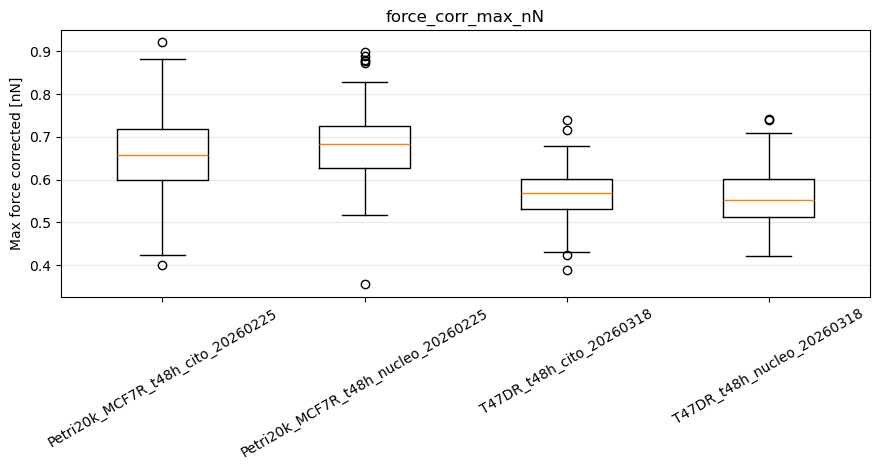

Salvato: afm_output/plots_qc/boxplot_force_corr_max_nN.png


/var/folders/2r/cxn1cvbn4s5_ychznfzgynd00000gn/T/ipykernel_8244/1739921662.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=groups, showfliers=True)


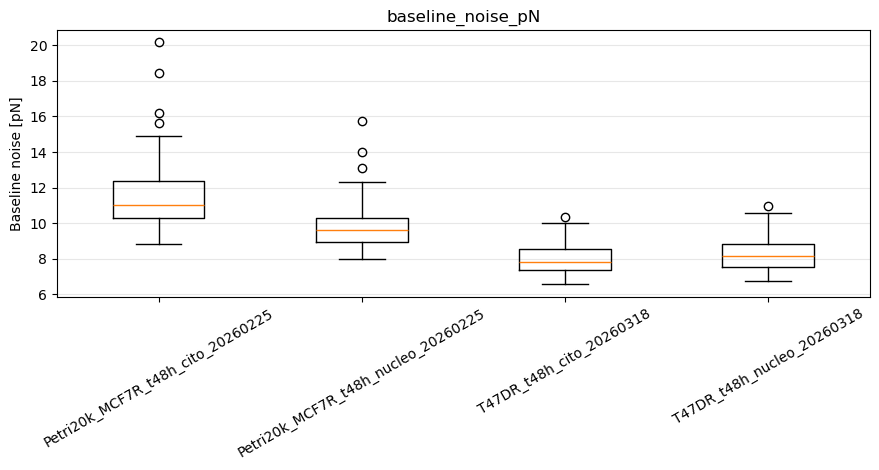

Salvato: afm_output/plots_qc/boxplot_baseline_noise_pN.png


/var/folders/2r/cxn1cvbn4s5_ychznfzgynd00000gn/T/ipykernel_8244/1739921662.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=groups, showfliers=True)


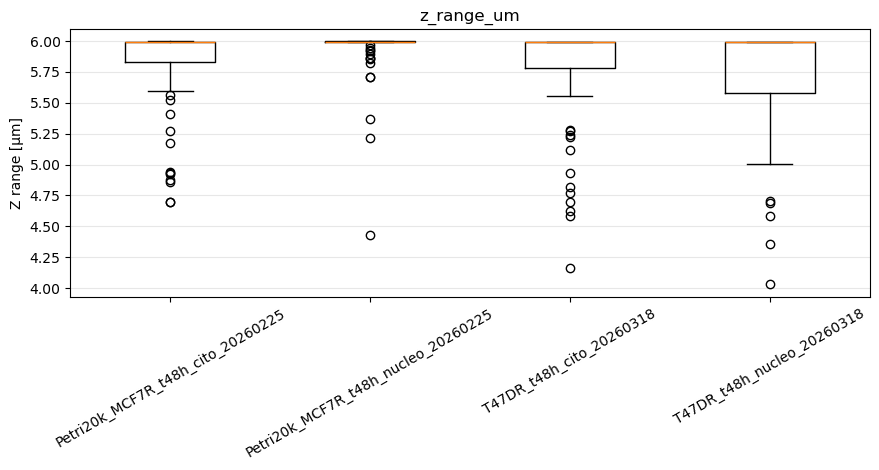

Salvato: afm_output/plots_qc/boxplot_z_range_um.png


/var/folders/2r/cxn1cvbn4s5_ychznfzgynd00000gn/T/ipykernel_8244/1739921662.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=groups, showfliers=True)


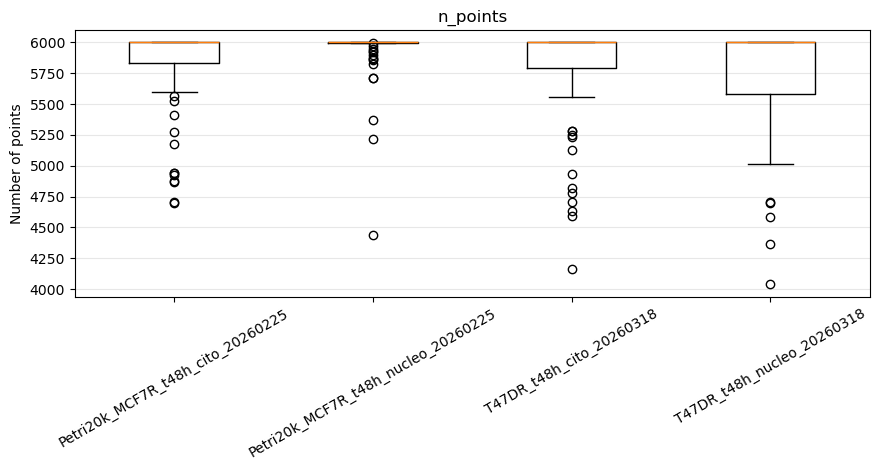

Salvato: afm_output/plots_qc/boxplot_n_points.png


/var/folders/2r/cxn1cvbn4s5_ychznfzgynd00000gn/T/ipykernel_8244/1739921662.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=groups, showfliers=True)


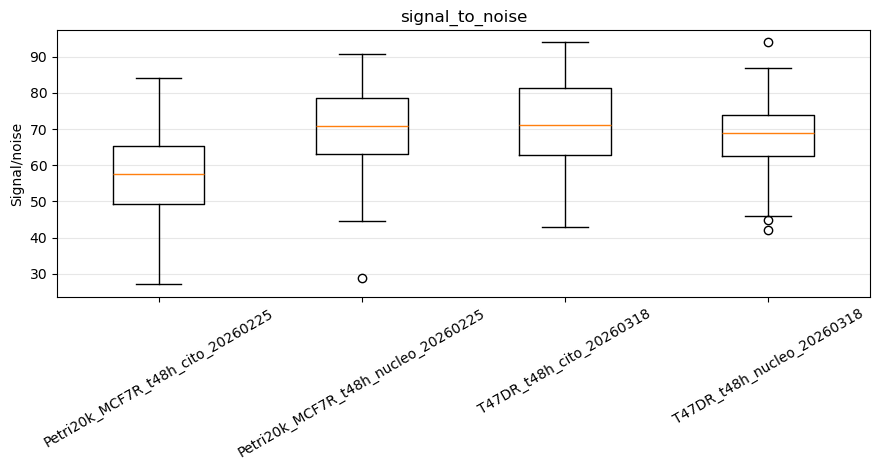

Salvato: afm_output/plots_qc/boxplot_signal_to_noise.png


/var/folders/2r/cxn1cvbn4s5_ychznfzgynd00000gn/T/ipykernel_8244/1739921662.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=groups, showfliers=True)


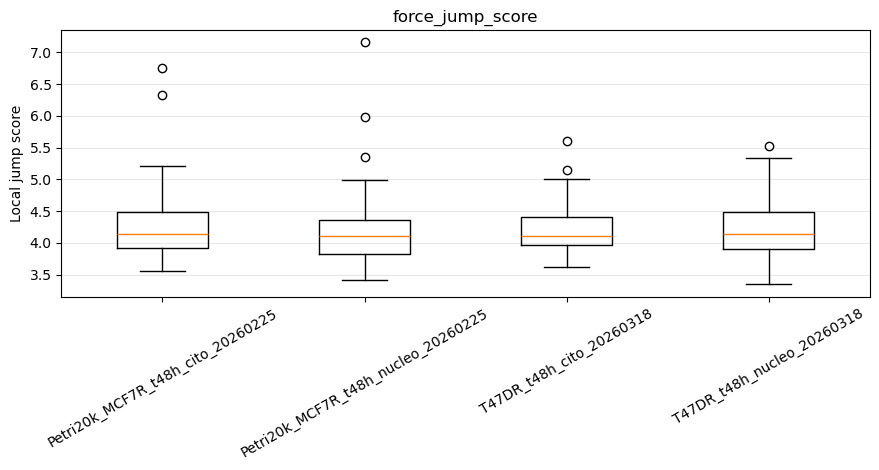

Salvato: afm_output/plots_qc/boxplot_force_jump_score.png


/var/folders/2r/cxn1cvbn4s5_ychznfzgynd00000gn/T/ipykernel_8244/1739921662.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=groups, showfliers=True)


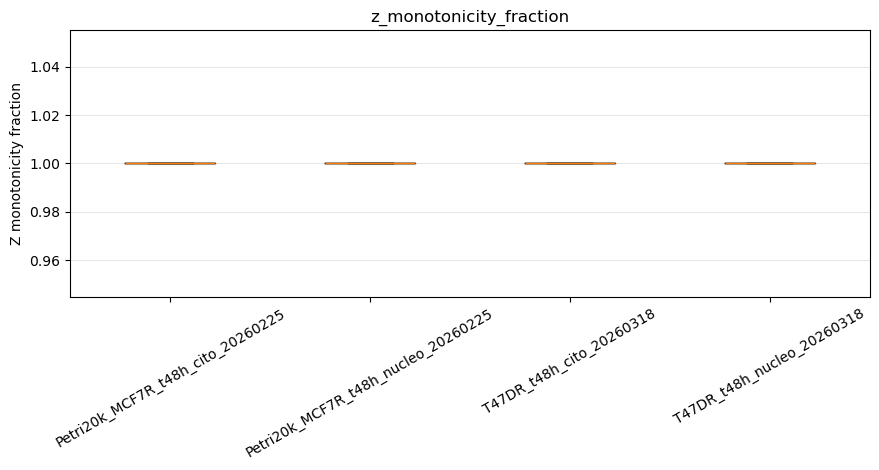

Salvato: afm_output/plots_qc/boxplot_z_monotonicity_fraction.png


In [15]:
def save_boxplot_by_group(df, col, ylabel=None, out_dir=QC_PLOTS_DIR):
    groups = list(df["group"].dropna().unique())
    data = [df.loc[df["group"] == g, col].dropna().to_numpy() for g in groups]

    fig, ax = plt.subplots(figsize=(9, 4.8))
    ax.boxplot(data, labels=groups, showfliers=True)
    ax.set_ylabel(ylabel or col)
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=30)
    ax.grid(alpha=0.3, axis="y")
    fig.tight_layout()

    out = out_dir / f"boxplot_{sanitize_name(col)}.png"
    fig.savefig(out, dpi=180, bbox_inches="tight")
    plt.show()
    print("Salvato:", out)


for col, ylabel in [
    ("force_corr_max_nN", "Max force corrected [nN]"),
    ("baseline_noise_pN", "Baseline noise [pN]"),
    ("z_range_um", "Z range [µm]"),
    ("n_points", "Number of points"),
    ("signal_to_noise", "Signal/noise"),
    ("force_jump_score", "Local jump score"),
    ("z_monotonicity_fraction", "Z monotonicity fraction"),
]:
    save_boxplot_by_group(ok, col, ylabel=ylabel)

In [16]:
def plot_segment0_csv_from_summary_row(row, out_dir=None):
    csv_path = Path(row["csv_path"])
    df = pd.read_csv(csv_path)

    z = df["z_tip_um"].to_numpy(dtype=float)
    f = df["force_nN"].to_numpy(dtype=float)

    segment_style = row.get("segment_style", "extend")
    baseline, noise_nN, region, _ = segment_baseline(f, segment_style, frac=BASELINE_FRACTION)
    f_corr = f - baseline

    fig, ax = plt.subplots(figsize=(7.5, 4.8))
    ax.plot(z, f_corr, lw=1)
    ax.axhline(0, color="black", lw=0.8, alpha=0.5)

    title = (
        f"{row['group']} / {row['file_name']}\n"
        f"QC group: {row.get('qc_reason_preliminary_group', 'NA')}"
    )
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("Vertical tip position [µm]")
    ax.set_ylabel("Force - preliminary baseline [nN]")
    ax.grid(alpha=0.3)
    fig.tight_layout()

    if out_dir is not None:
        out_dir = Path(out_dir)
        out_dir.mkdir(parents=True, exist_ok=True)
        out = out_dir / f"{sanitize_name(row['group'])}__{sanitize_name(Path(str(row['file_name'])).stem)}_segment0.png"
        fig.savefig(out, dpi=180, bbox_inches="tight")
        plt.close(fig)
        return out

    plt.show()
    return None


if SAVE_ALL_OVERVIEW_PLOTS:
    saved = []
    errors = []
    for i, p in enumerate(files, start=1):
        try:
            saved.append(plot_curve_overview(Path(p), save=True))
        except Exception as e:
            errors.append({"file": str(p), "error": repr(e)})
        if i % 50 == 0:
            print(f"Plot overview processati {i}/{len(files)}...")

    if errors:
        errors_df = pd.DataFrame(errors)
        errors_path = REPORTS_DIR / "plot_overview_errors.csv"
        errors_df.to_csv(errors_path, index=False)
        print("Errori plot overview:", len(errors), "->", errors_path)

    print("Plot overview salvati:", len(saved), "in", PLOTS_DIR)


if SAVE_QC_EXAMPLE_PLOTS:
    examples_dir = QC_PLOTS_DIR / "example_curves"
    examples_dir.mkdir(parents=True, exist_ok=True)

    n_each = 5
    sampled_rows = []

    not_flagged = ok[~ok["qc_flag_preliminary_any"]]
    if len(not_flagged) > 0:
        sampled_rows.append(not_flagged.sample(min(n_each, len(not_flagged)), random_state=1))

    flagged = ok[ok["qc_flag_preliminary_any"]].sort_values("qc_score_preliminary_group", ascending=False)
    if len(flagged) > 0:
        sampled_rows.append(flagged.head(n_each))

    for key in ["baseline_noise_pN", "z_range_um", "force_corr_max_nN", "force_jump_score", "n_points"]:
        sub = ok[ok["qc_reason_preliminary_group"].str.contains(key, na=False)]
        if len(sub) > 0:
            sampled_rows.append(sub.head(n_each))

    if sampled_rows:
        sample_df = pd.concat(sampled_rows, ignore_index=True).drop_duplicates(subset=["csv_path"])
        saved_examples = []
        for _, row in sample_df.iterrows():
            try:
                saved_examples.append(plot_segment0_csv_from_summary_row(row, out_dir=examples_dir))
            except Exception as e:
                print("Example plot error:", row.get("csv_path"), e)
        print("Plot esempio QC salvati:", len(saved_examples), "in", examples_dir)
    else:
        print("No example curve to plot.")

Plot overview processati 50/257...
Plot overview processati 100/257...
Plot overview processati 150/257...
Plot overview processati 200/257...
Plot overview processati 250/257...
Plot overview salvati: 257 in afm_output/plots_overview
Plot esempio QC salvati: 23 in afm_output/plots_qc/example_curves


## 10. Manifest for notebook 02

In [17]:
manifest_cols = [
    "file",
    "file_name",
    "group",
    "cell_line",
    "region",
    "time_h",
    "date",
    "seeding",
    "csv_path",
    "segment_id",
    "segment_style",
    "segment_name",
    "analysis_role",
    "n_points",
    "z_direction",
    "z_monotonicity_fraction",
    "baseline_nN",
    "baseline_noise_pN",
    "baseline_region",
    "force_corr_max_nN",
    "signal_to_noise",
    "force_jump_score",
    "spring_N_per_m",
    "sensitivity_m_per_V",
    "cantilever_name",
    "tip_radius",
    "tip_half_angle",
    "qc_score_preliminary_global",
    "qc_flag_preliminary_global",
    "qc_reason_preliminary_global",
    "qc_score_preliminary_group",
    "qc_flag_preliminary_group",
    "qc_reason_preliminary_group",
    "qc_flag_preliminary_any",
]

manifest = ok[[c for c in manifest_cols if c in ok.columns]].copy()

manifest_path = MANIFEST_DIR / "segment0_manifest.csv"
manifest.to_csv(manifest_path, index=False)

print("Manifest notebook 02 salvato:", manifest_path)
display(manifest.head())

Manifest notebook 02 salvato: afm_output/manifests/segment0_manifest.csv


,file,file_name,group,cell_line,region,time_h,date,seeding,csv_path,segment_id,segment_style,segment_name,analysis_role,n_points,z_direction,z_monotonicity_fraction,baseline_nN,baseline_noise_pN,baseline_region,force_corr_max_nN,signal_to_noise,force_jump_score,spring_N_per_m,sensitivity_m_per_V,cantilever_name,tip_radius,tip_half_angle,qc_score_preliminary_global,qc_flag_preliminary_global,qc_reason_preliminary_global,qc_score_preliminary_group,qc_flag_preliminary_group,qc_reason_preliminary_group,qc_flag_preliminary_any
0,Curve di forza belle/Petri20k_MCF7R_t48h_cito_...,cito-0000.jpk-force,Petri20k_MCF7R_t48h_cito_20260225,MCF7R,cito,48,20260225,Petri20k,afm_output/csv_curves/Petri20k_MCF7R_t48h_cito...,0,extend,extend-spm,mechanical_fit_candidate,6000,decreasing,1.0,0.021959,12.778282,start_of_extend_far_from_surface,0.609161,47.671563,5.190048,0.118829,1.090279e-08,MLCT-BIO-Triangular,NaN,NaN,2.781473,False,ok,2.816221,False,ok,False
1,Curve di forza belle/Petri20k_MCF7R_t48h_cito_...,cito-0005.jpk-force,Petri20k_MCF7R_t48h_cito_20260225,MCF7R,cito,48,20260225,Petri20k,afm_output/csv_curves/Petri20k_MCF7R_t48h_cito...,0,extend,extend-spm,mechanical_fit_candidate,4700,decreasing,1.0,0.034312,11.057050,start_of_extend_far_from_surface,0.706989,63.940088,4.130746,0.118829,1.090279e-08,MLCT-BIO-Triangular,NaN,NaN,545.355224,True,z_range_um_low_outlier,475.137499,True,z_range_um_low_outlier,True
2,Curve di forza belle/Petri20k_MCF7R_t48h_cito_...,cito-0006.jpk-force,Petri20k_MCF7R_t48h_cito_20260225,MCF7R,cito,48,20260225,Petri20k,afm_output/csv_curves/Petri20k_MCF7R_t48h_cito...,0,extend,extend-spm,mechanical_fit_candidate,5413,decreasing,1.0,0.025869,10.533824,start_of_extend_far_from_surface,0.570457,54.154761,5.206711,0.118829,1.090279e-08,MLCT-BIO-Triangular,NaN,NaN,245.608188,True,z_range_um_low_outlier,214.134284,True,z_range_um_low_outlier,True
3,Curve di forza belle/Petri20k_MCF7R_t48h_cito_...,cito-0007.jpk-force,Petri20k_MCF7R_t48h_cito_20260225,MCF7R,cito,48,20260225,Petri20k,afm_output/csv_curves/Petri20k_MCF7R_t48h_cito...,0,extend,extend-spm,mechanical_fit_candidate,6000,decreasing,1.0,0.102729,10.392184,start_of_extend_far_from_surface,0.553840,53.293868,3.977025,0.118829,1.090279e-08,MLCT-BIO-Triangular,NaN,NaN,1.215829,False,ok,1.160165,False,ok,False
4,Curve di forza belle/Petri20k_MCF7R_t48h_cito_...,cito-0008.jpk-force,Petri20k_MCF7R_t48h_cito_20260225,MCF7R,cito,48,20260225,Petri20k,afm_output/csv_curves/Petri20k_MCF7R_t48h_cito...,0,extend,extend-spm,mechanical_fit_candidate,6000,decreasing,1.0,0.046276,11.176091,start_of_extend_far_from_surface,0.767406,68.664955,4.129775,0.118829,1.090279e-08,MLCT-BIO-Triangular,NaN,NaN,1.600985,False,ok,1.208547,False,ok,False


## 11. Final report, run info and README of the outputs

In [18]:
run_info = {
    "created_at": datetime.now().isoformat(timespec="seconds"),
    "python": sys.version,
    "platform": platform.platform(),
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "matplotlib": plt.matplotlib.__version__,
    "data_dir": str(DATA_DIR.resolve()),
    "out_dir": str(OUT_DIR.resolve()),
    "n_jpk_files": int(len(files)),
    "n_csv_exported": int(len(csv_exported)),
    "n_metadata_segments": int(len(metadata_segments)),
    "n_segment0_curves": int(len(ok)),
    "n_preliminary_flagged_global": int(ok["qc_flag_preliminary_global"].sum()),
    "n_preliminary_flagged_group": int(ok["qc_flag_preliminary_group"].sum()),
    "n_preliminary_flagged_any": int(ok["qc_flag_preliminary_any"].sum()),
    "baseline_fraction": BASELINE_FRACTION,
    "qc_z_threshold": QC_Z_THRESHOLD,
}

run_info_path = META_DIR / "run_info.json"
with open(run_info_path, "w", encoding="utf-8") as f:
    json.dump(run_info, f, indent=2, ensure_ascii=False)

pd.Series(run_info).to_csv(META_DIR / "run_info.csv", header=["value"])

readme_text = f"""
AFM output generated by 01_JPK_reader_and_preliminary_QC.ipynb
Generated at: {run_info["created_at"]}

Important methodological note
-----------------------------
No curves are removed at this stage.
Preliminary QC flags are diagnostic only.

Folders
-------
csv_curves/
    One CSV per JPK segment. Subfolders are experimental groups.
    *_segment0.csv = extend/approach, candidate for mechanical fit.
    *_segment1.csv = retract, useful for adhesion/hysteresis analysis.

metadata/
    file_catalog.csv              : one row per .jpk-force file.
    metadata_segments.csv         : one row per file/segment.
    metadata_properties_long.csv  : full JPK properties in long format.
    csv_export_manifest.csv       : one row per exported CSV.
    run_info.json/csv             : software versions and run summary.

summaries/
    summary_segment0.csv
        One row per segment0 curve, no QC scores.
    summary_segment0_with_preliminary_qc.csv
        One row per segment0 curve, with preliminary instrumental QC.
    data_quality_by_group.csv
        Aggregate QC summary by experimental group.

manifests/
    segment0_manifest.csv
        Input file for notebook 02_preprocessing_contact_point.ipynb.

plots_overview/
    Overview plots for all curves with segment0/segment1 and preliminary baseline.

plots_qc/
    Boxplots of QC features and example curves.

Next notebook
-------------
02_preprocessing_contact_point.ipynb
    Uses manifests/segment0_manifest.csv and csv_curves/*/*_segment0.csv.
    Performs baseline refinement, contact point detection, indentation construction,
    and contact-point QC.
"""

readme_path = OUT_DIR / "README_outputs.txt"
with open(readme_path, "w", encoding="utf-8") as f:
    f.write(readme_text)

excluded_path = OUT_DIR / "excluded_nothing_yet.txt"
with open(excluded_path, "w", encoding="utf-8") as f:
    f.write(
        "No curves are excluded in notebook 01.\n"
        "Preliminary QC flags are diagnostic only and must not be interpreted as final good/bad labels.\n"
    )

print("run_info salvato:", run_info_path)
print("README salvato:", readme_path)
print("Nota esclusione salvata:", excluded_path)

print("\n===== FINAL REPORT =====")
for k, v in run_info.items():
    print(f"{k}: {v}")

print("\nOutput principali:")
print("-", summary_path)
print("-", summary_qc_path)
print("-", quality_path)
print("-", manifest_path)
print("-", readme_path)

run_info salvato: afm_output/metadata/run_info.json
README salvato: afm_output/README_outputs.txt
Nota esclusione salvata: afm_output/excluded_nothing_yet.txt

===== FINAL REPORT =====
created_at: 2026-06-06T18:19:43
python: 3.12.13 | packaged by conda-forge | (main, Mar  5 2026, 17:06:14) [Clang 19.1.7 ]
platform: macOS-26.5.1-arm64-arm-64bit
pandas: 3.0.3
numpy: 2.4.6
matplotlib: 3.10.9
data_dir: /Users/gmoretti/Work/AFM/Code_General/Curve di forza belle
out_dir: /Users/gmoretti/Work/AFM/Code_General/afm_output
n_jpk_files: 257
n_csv_exported: 514
n_metadata_segments: 514
n_segment0_curves: 257
n_preliminary_flagged_global: 85
n_preliminary_flagged_group: 85
n_preliminary_flagged_any: 86
baseline_fraction: 0.2
qc_z_threshold: 3.5

Output principali:
- afm_output/summaries/summary_segment0.csv
- afm_output/summaries/summary_segment0_with_preliminary_qc.csv
- afm_output/summaries/data_quality_by_group.csv
- afm_output/manifests/segment0_manifest.csv
- afm_output/README_outputs.txt


## End of notebook 01

The next notebook is `02_preprocessing_contact_point.ipynb`.

Main inputs produced here:

```text
afm_output/manifests/segment0_manifest.csv
afm_output/csv_curves/*/*_segment0.csv
afm_output/summaries/summary_segment0_with_preliminary_qc.csv
```

Notebook 02 handles:
- baseline refinement;
- contact point;
- indentation;
- contact-point QC;
- Hertz-like fit;
- curve-by-curve diagnostic plots.